In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy

# visualize root of unity solutions
from utils import ratemap_collage, block_diag

In [2]:
def block_rotation(omegas):
    blocks = []
    for omega in omegas:
        block = np.array([[np.cos(omega), -np.sin(omega)], [np.sin(omega), np.cos(omega)]])
        blocks.append(block)
    return scipy.linalg.block_diag(*blocks)

In [3]:
n = 20
n_copies = 1

In [4]:
phi = np.arange(0, n)* np.pi/n 
phi_plot = np.concatenate([phi, phi + np.pi])  # add negative rotations
phi = np.concatenate([phi for _ in range(n_copies)])

theta = np.linspace(0, 2*np.pi, 100)

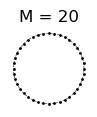

In [5]:
plt.figure(figsize = (1,1))
plt.title(f"M = {n}")
plt.plot(np.cos(theta), np.sin(theta), 'k--', alpha = 0.75, linewidth = 0.5)
plt.plot(np.cos(phi_plot), np.sin(phi_plot), 'ko', markersize = 1)
plt.axis("equal")
plt.axis("off")
# plt.subplots_adjust(top=0.99)
plt.savefig(f"./figures/RoU_roots_M={n}.svg",dpi = 300, transparent = True, bbox_inches = "tight")

In [6]:
R = scipy.stats.ortho_group.rvs(2*n*n_copies)

p0 = R.T@ np.ones(2*n*n_copies)
p0 /= np.linalg.norm(p0)

In [7]:
delta_x = np.linspace(-1, 1, 64)*10
delta_y = np.linspace(-1, 1, 64)*10
dx, dy = np.meshgrid(delta_x, delta_y)
dr = np.stack((dx.ravel(), dy.ravel()), axis = 1)

alpha = np.zeros((len(dr), 2*n*n_copies))
alpha_0 = R@p0

for i in range(len(dr)):
    omegas = dr[i,0]*np.cos(phi) + dr[i,1]*np.sin(phi)
    Q = block_rotation(omegas)
    alpha[i,:] = Q @ alpha_0

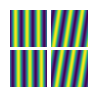

In [8]:
ratemap_collage(alpha.T.reshape(-1, len(delta_x), len(delta_y)), 2, 2, figsize = (1, 1))
plt.savefig(f"./figures/RoU_M={n}_alpha.svg", dpi = 300, transparent = True, bbox_inches = "tight")

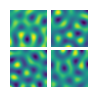

In [9]:
p = R.T @ alpha.T 
ratemap_collage(p.reshape(-1, len(delta_x), len(delta_y)), 2, 2, figsize = (1, 1))
plt.savefig(f"./figures/RoU_M={n}_p.svg", dpi = 300, transparent = True, bbox_inches = "tight")

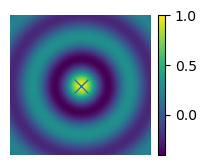

In [10]:
plt.figure(figsize=(2,2))
plt.imshow(np.sum(p.reshape(2*n*n_copies, 64, 64)[:,32, 32,None,None]*p.reshape(2*n*n_copies, 64,64),axis=0))
plt.plot(32,32, "x", markersize = 10)
plt.colorbar(fraction = 0.045)
plt.axis("off")
plt.savefig(f"./figures/RoU_M={n}_sim.svg", dpi = 300, transparent = True, bbox_inches = "tight")